#Anomaly Detector

##Exploratory Data Analysis

###Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

# Feature Engineering Step #2
from scipy import stats
from scipy.stats import normaltest

###Load the Dataset and Preview

In [ ]:
#Connect to the Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/FYP/web-ids23_benign.csv')

# Drop all rows with any null values
df = df.dropna()

print("Dataset Overview:")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nFirst few rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
print(df.describe())

Mounted at /content/drive
Dataset Overview:
Shape: (773805, 38)
Columns: ['uid', 'ts', 'id.orig_h', 'id.resp_h', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'payload_bytes_per_second', 'fwd_init_window_size', 'bwd_init_window_size', 'fwd_last_window_size', 'bwd_last_window_size', 'traffic_direction', 'attack', 'attack_type']

First few rows:
                    uid                             ts        id.orig_h  \
0  b_CfXdFr3sW9WsL5f6uf  2023-07-05 02:17:29.148539904  192.168.100.115   
1  b_C

##Feature Engineering

In [ ]:
# Identify data types and Differentiate the columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\nNumerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

df_engineered = df.copy()

# 1. Handle categorical variables
label_encoders = {}
for col in categorical_cols:
    if col != 'attack':  # Don't encode target variable yet
        le = LabelEncoder()
        df_engineered[col + '_encoded'] = le.fit_transform(df_engineered[col].astype(str))
        label_encoders[col] = le


Numerical columns (30): ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'payload_bytes_per_second', 'fwd_init_window_size', 'bwd_init_window_size', 'fwd_last_window_size', 'bwd_last_window_size']
Categorical columns (8): ['uid', 'ts', 'id.orig_h', 'id.resp_h', 'service', 'traffic_direction', 'attack', 'attack_type']


### 1. Variance based Feature Selection

In [ ]:
# ================================================================================
# PHASE 1: VARIANCE-BASED FEATURE SELECTION FOR ANOMALY DETECTION
# ================================================================================

def variance_based_analysis(df):
    """
    If a feature has near-zero variance, it means most of its values are nearly identical,
    making it less useful for distinguishing between different classes

    Select features with moderate variance for robust normal space definition.
    """
    print("\n" + "="*60)
    print("PHASE 1: VARIANCE-BASED FEATURE SELECTION FOR ANOMALY DETECTION")
    print("="*60)

    # Exclude non-numeric and identifier columns
    exclude_cols = ['uid', 'ts', 'id.orig_h', 'id.resp_h', 'service', 'traffic_direction', 'attack', 'attack_type']
    numeric_cols = [col for col in df.columns if col not in exclude_cols and pd.api.types.is_numeric_dtype(df[col])]

    variance_stats = []

    for col in numeric_cols:
        if df[col].std() != 0:
            cv = df[col].std() / df[col].mean() if df[col].mean() != 0 else np.inf

            # Categorize for anomaly detection
            if cv < 0.01:
                suitability = "Poor (too rigid)"
            elif 0.01 <= cv <= 0.5:
                suitability = "Good"
            elif 0.5 < cv <= 2.0:
                suitability = "Excellent"
            else:
                suitability = "Caution (too noisy)"

            variance_stats.append({
                'feature': col,
                'coefficient_variation': cv,
                'suitability': suitability
            })

    variance_df = pd.DataFrame(variance_stats)
    variance_df = variance_df.sort_values('coefficient_variation', ascending=False)

    # Show results
    print("\nFeature Suitability for Anomaly Detection:")
    for suit in ['Excellent', 'Good', 'Poor (too rigid)', 'Caution (too noisy)']:
        features = variance_df[variance_df['suitability'] == suit]
        print(f"\n{suit}: {len(features)} features")
        if len(features) > 0:
            print(features[['feature', 'coefficient_variation']].to_string(index=False))

    # Get recommended features (CV between 0.01 and 2.0)
    recommended = variance_df[variance_df['suitability'].isin(['Good', 'Excellent'])]
    recommended_features = recommended['feature'].tolist()

    print(f"\n✅ Recommended for anomaly detection: {len(recommended_features)} features")
    print(recommended_features)
    return variance_df, numeric_cols, recommended_features

# Usage
variance_df, numeric_cols, recommended_features = variance_based_analysis(df)


PHASE 1: VARIANCE-BASED FEATURE SELECTION FOR ANOMALY DETECTION

Feature Suitability for Anomaly Detection:

Excellent: 8 features
             feature  coefficient_variation
 flow_FIN_flag_count               1.222890
bwd_init_window_size               1.207663
 flow_SYN_flag_count               1.188849
fwd_init_window_size               1.187969
 fwd_header_size_max               0.744981
 bwd_header_size_max               0.742181
 bwd_header_size_min               0.658913
 fwd_header_size_min               0.650725

Good: 1 features
      feature  coefficient_variation
down_up_ratio               0.144109

Poor (too rigid): 0 features

Caution (too noisy): 17 features
                 feature  coefficient_variation
payload_bytes_per_second              17.077421
       bwd_data_pkts_tot               7.019395
            bwd_pkts_tot               5.678924
    fwd_last_window_size               4.765915
    bwd_last_window_size               4.342379
      bwd_PSH_flag_count    

### 2. Distribution Analysis of Benign Traffic

In [ ]:
# ================================================================================
# PHASE 2: DISTRIBUTION ANALYSIS OF BENIGN TRAFFIC FOR ANOMALY DETECTION
# ================================================================================
def distribution_analysis_one_class(df, numeric_cols):
    """
    Skewness: Measures if data leans left/right (symmetric = 0)
    Kurtosis: Measures tail heaviness (normal = 3)
    """
    print("\n" + "="*60)
    print("DISTRIBUTION ANALYSIS FOR ONE-CLASS TRAINING")
    print("="*60)

    distribution_stats = []

    for col in numeric_cols:
        data = df[col].dropna()
        if len(data) > 0:
            # Core statistics
            skewness = stats.skew(data)
            kurtosis = stats.kurtosis(data)

            # Normality test
            try:
                normality_stat, normality_p = normaltest(data)
                is_normal = normality_p > 0.05
            except:
                is_normal = False
                normality_p = 0

            # Percentiles for anomaly thresholds
            percentiles = np.percentile(data, [25, 50, 75, 95, 99])

            # Outlier ratio using IQR
            q1, q3 = percentiles[0], percentiles[2]
            iqr = q3 - q1
            outliers = np.sum((data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr))
            outlier_ratio = outliers / len(data)

            distribution_stats.append({
                'feature': col,
                'skewness': skewness,
                'kurtosis': kurtosis,
                'is_normal': is_normal,
                'outlier_ratio': outlier_ratio,
                'q95': percentiles[3],
                'q99': percentiles[4],
                'scaling': 'robust' if abs(skewness) > 2 or outlier_ratio > 0.1 else 'standard'
            })

    dist_df = pd.DataFrame(distribution_stats)

    # Key insights for One-Class SVM
    avg_outlier_ratio = dist_df['outlier_ratio'].mean()
    recommended_nu = max(0.05, avg_outlier_ratio)  # Default 5% contamination

    print(f"Features analyzed: {len(dist_df)}")
    print(f"Normal distribution: {dist_df['is_normal'].sum()}")
    print(f"Robust scaling needed: {(dist_df['scaling'] == 'robust').sum()}")
    print(f"Recommended nu parameter: {recommended_nu:.3f}")

    print("\nTop 30 most skewed features:")
    top_skewed = dist_df.nlargest(30, 'skewness', keep='all')[['feature', 'skewness', 'scaling']]
    print(top_skewed)

    # Print columns needing robust scaling
    robust_cols = dist_df[dist_df['scaling'] == 'robust']['feature'].tolist()
    standard_cols = dist_df[dist_df['scaling'] == 'standard']['feature'].tolist()

    print(f"\nCOLUMNS NEEDING ROBUST SCALING ({len(robust_cols)}):")
    for col in robust_cols:
        skew_val = dist_df[dist_df['feature'] == col]['skewness'].iloc[0]
        outlier_val = dist_df[dist_df['feature'] == col]['outlier_ratio'].iloc[0]
        print(f"  {col} (skew: {skew_val:.2f}, outliers: {outlier_val:.3f})")

    print(f"\nCOLUMNS NEEDING STANDARD SCALING ({len(standard_cols)}):")
    for col in standard_cols[:len(standard_cols)]:  # Show first 5
        print(f"  {col}")
    if len(standard_cols) > 5:
        print(f"  ... and {len(standard_cols) - 5} more")

    return dist_df, recommended_nu

dist_df, recommended_nu = distribution_analysis_one_class(df, numeric_cols)


DISTRIBUTION ANALYSIS FOR ONE-CLASS TRAINING
Features analyzed: 30
Normal distribution: 0
Robust scaling needed: 18
Recommended nu parameter: 0.081

Top 30 most skewed features:
                     feature    skewness   scaling
4          bwd_data_pkts_tot  134.614399    robust
2               bwd_pkts_tot  111.375319    robust
3          fwd_data_pkts_tot   37.773487    robust
12       bwd_header_size_tot   27.100626    robust
19        bwd_PSH_flag_count   23.781390    robust
25  payload_bytes_per_second   23.551059    robust
20       flow_ACK_flag_count   21.617407    robust
29      bwd_last_window_size   21.116415    robust
18        fwd_PSH_flag_count   20.606761    robust
28      fwd_last_window_size   19.220716    robust
1               fwd_pkts_tot   18.020883    robust
9        fwd_header_size_tot   17.557968    robust
0              flow_duration    6.034727    robust
8              down_up_ratio    5.804038    robust
5           fwd_pkts_per_sec    4.692514    robust
7    

In [ ]:
# ================================================================================
# PHASE 2: DISTRIBUTION ANALYSIS - Implement the suggestion
# ================================================================================
def apply_scaling_transformation(df, dist_df):
    """
    Apply scaling transformations based on distribution analysis
    """
    from sklearn.preprocessing import RobustScaler, StandardScaler

    scaled_df = df.copy()
    scaler_dict = {}

    robust_features = dist_df[dist_df['scaling'] == 'robust']['feature'].tolist()
    standard_features = dist_df[dist_df['scaling'] == 'standard']['feature'].tolist()

    print("Applying scaling transformations...")

    # Apply robust scaling
    if robust_features:
        robust_scaler = RobustScaler()
        scaled_df[robust_features] = robust_scaler.fit_transform(df[robust_features])
        scaler_dict['robust'] = (robust_scaler, robust_features)
        print(f"RobustScaler applied to {len(robust_features)} features")

    # Apply standard scaling
    if standard_features:
        standard_scaler = StandardScaler()
        scaled_df[standard_features] = standard_scaler.fit_transform(df[standard_features])
        scaler_dict['standard'] = (standard_scaler, standard_features)
        print(f"StandardScaler applied to {len(standard_features)} features")

    return scaled_df, scaler_dict

### 3. Feature Stability Analysis

In [ ]:
# ====================================================================
# PHASE 3: FEATURE STABILITY ANALYSIS
# ====================================================================

def stability_analysis(df, numeric_cols):
    """
    Identify which features remain consistent across different services and time periods
    for reliable anomaly detection.
    """
    print("\n" + "="*60)
    print("PHASE 3: FEATURE STABILITY ANALYSIS")
    print("="*60)

    stability_stats = []

    # Service-specific analysis if 'service' column exists
    if 'service' in df.columns:
        print("\nService Distribution:")
        service_counts = df['service'].value_counts()
        print(service_counts.head(10))

        # Analyze feature stability across services
        services = df['service'].value_counts().head(5).index.tolist()

        for col in numeric_cols:  # Analyze top 10 features for performance
            service_stats = []
            for service in services:
                service_data = df[df['service'] == service][col].dropna()
                if len(service_data) > 10:  # Minimum sample size
                    service_stats.append({
                        'service': service,
                        'mean': service_data.mean(),
                        'std': service_data.std(),
                        'cv': service_data.std() / service_data.mean() if service_data.mean() != 0 else np.inf
                    })

            if service_stats:
                service_df = pd.DataFrame(service_stats)
                cv_range = service_df['cv'].max() - service_df['cv'].min()
                mean_cv = service_df['cv'].mean()

                stability_stats.append({
                    'feature': col,
                    'service_cv_range': cv_range,
                    'mean_service_cv': mean_cv,
                    'service_consistency': 1 / (1 + cv_range)  # Higher is more consistent
                })

    # Temporal analysis if timestamp exists
    if 'ts' in df.columns:
        print("\nTemporal Analysis:")
        df['ts'] = pd.to_datetime(df['ts'], unit='s', errors='coerce')

        if df['ts'].notna().sum() > 0:
            print(f"Time range: {df['ts'].min()} to {df['ts'].max()}")

            # Create time bins for analysis
            df['time_bin'] = pd.cut(df['ts'], bins=10, labels=False)

            temporal_stability = []
            for col in numeric_cols[:10]:
                time_stats = []
                for time_bin in range(10):
                    bin_data = df[df['time_bin'] == time_bin][col].dropna()
                    if len(bin_data) > 10:
                        time_stats.append(bin_data.mean())

                if len(time_stats) > 5:
                    temporal_cv = np.std(time_stats) / np.mean(time_stats) if np.mean(time_stats) != 0 else np.inf
                    temporal_stability.append({
                        'feature': col,
                        'temporal_cv': temporal_cv
                    })

            temp_df = pd.DataFrame(temporal_stability)
            temp_df = temp_df.sort_values('temporal_cv')
            print("\nMost Temporally Stable Features:")
            print(temp_df.head(10))

    if stability_stats:
        stability_df = pd.DataFrame(stability_stats)
        stability_df = stability_df.sort_values('service_consistency', ascending=False)

        print("\nMost Service-Consistent Features:")
        print(stability_df)

        return stability_df
    else:
        return pd.DataFrame()

stability_df = stability_analysis(df, numeric_cols)


PHASE 3: FEATURE STABILITY ANALYSIS

Service Distribution:
service
dns         445864
ssl         217281
http         59393
smtp         39651
ntp           6958
ftp-data      4161
ssh            321
ftp            105
ayiya           71
Name: count, dtype: int64

Temporal Analysis:

Most Service-Consistent Features:
                     feature  service_cv_range  mean_service_cv  \
11       fwd_header_size_max          0.033560         0.009712   
14       bwd_header_size_max          0.034994         0.017524   
13       bwd_header_size_min          0.068755         0.035963   
8              down_up_ratio          0.187898         0.105108   
10       fwd_header_size_min          0.210115         0.046341   
1               fwd_pkts_tot          1.935367         0.762863   
9        fwd_header_size_tot          1.942815         0.762389   
3          fwd_data_pkts_tot          2.445813         0.802014   
12       bwd_header_size_tot          2.680985         0.885306   
2         

### 4. Correlation and Redundancy Analysis


PHASE 4: CORRELATION AND REDUNDANCY ANALYSIS

Highly Correlated Feature Pairs (|correlation| > 0.9): 42
                feature1              feature2  correlation
38   flow_SYN_flag_count  fwd_init_window_size     0.999260
22   fwd_header_size_max  fwd_init_window_size     0.998896
33   bwd_header_size_max  fwd_init_window_size     0.998740
21   fwd_header_size_max   flow_SYN_flag_count     0.998141
32   bwd_header_size_max   flow_SYN_flag_count     0.998010
6       fwd_pkts_per_sec     flow_pkts_per_sec     0.997998
7       bwd_pkts_per_sec     flow_pkts_per_sec     0.997786
19   fwd_header_size_max   bwd_header_size_max     0.997709
26   bwd_header_size_min   bwd_header_size_max     0.995907
29   bwd_header_size_min  fwd_init_window_size     0.993799
28   bwd_header_size_min   flow_SYN_flag_count     0.993069
18   fwd_header_size_max   bwd_header_size_min     0.992844
5       fwd_pkts_per_sec      bwd_pkts_per_sec     0.991583
0           fwd_pkts_tot   fwd_header_size_tot     0.99

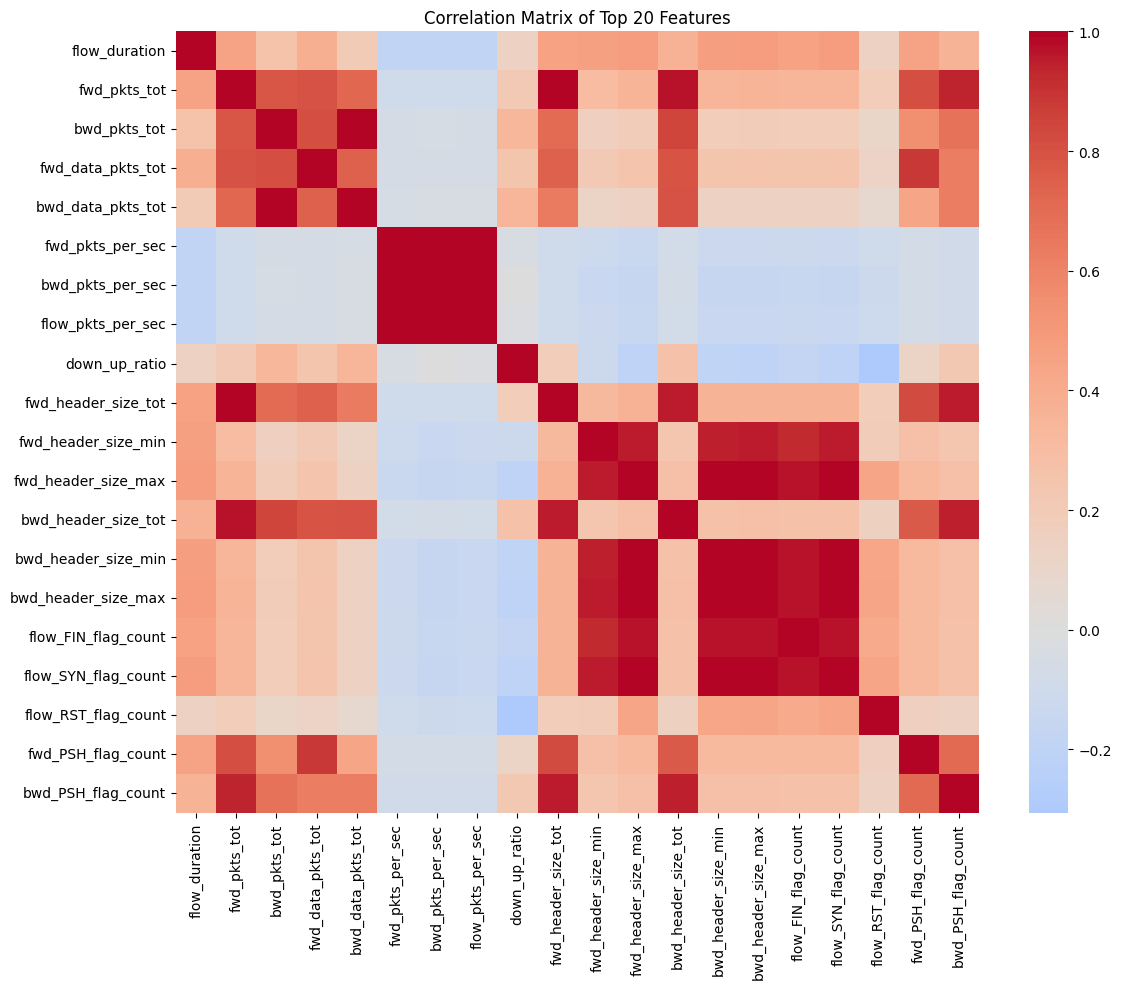

In [ ]:
# ====================================================================
# PHASE 4: CORRELATION AND REDUNDANCY ANALYSIS
# ====================================================================

def correlation_analysis(df, numeric_cols):
    """
    Identify and remove redundant features that provide duplicate information.
    """
    print("\n" + "="*60)
    print("PHASE 4: CORRELATION AND REDUNDANCY ANALYSIS")
    print("="*60)

    # Calculate correlation matrix
    correlation_matrix = df[numeric_cols].corr()

    # Find highly correlated feature pairs
    high_corr_pairs = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i+1, len(correlation_matrix.columns)):
            corr_val = correlation_matrix.iloc[i, j]
            if abs(corr_val) > 0.9:  # High correlation threshold
                high_corr_pairs.append({
                    'feature1': correlation_matrix.columns[i],
                    'feature2': correlation_matrix.columns[j],
                    'correlation': corr_val
                })

    if high_corr_pairs:
        corr_df = pd.DataFrame(high_corr_pairs)
        corr_df = corr_df.sort_values('correlation', key=abs, ascending=False)

        print(f"\nHighly Correlated Feature Pairs (|correlation| > 0.9): {len(high_corr_pairs)}")
        print(corr_df)  # Show all pairs instead of just head(15)

        # Suggest features to remove
        features_to_remove = set()
        for _, row in corr_df.iterrows():
            if row['feature1'] not in features_to_remove:
                features_to_remove.add(row['feature2'])

        print(f"\nSuggested features to remove due to high correlation: {len(features_to_remove)}")
        print(list(features_to_remove))  # Show all features instead of just [:10]

    # Plot correlation heatmap for selected features
    plt.figure(figsize=(12, 10))
    selected_features = numeric_cols[:20]  # Top 20 features for visualization
    corr_subset = correlation_matrix.loc[selected_features, selected_features]
    sns.heatmap(corr_subset, annot=False, cmap='coolwarm', center=0)
    plt.title('Correlation Matrix of Top 20 Features')
    plt.tight_layout()
    plt.show()

    return correlation_matrix, high_corr_pairs

matrix, high_corr_pairs = correlation_analysis(df, numeric_cols)

### Final feature selection model

In [ ]:
# ====================================================================
# FINAL FEATURE SELECTION FOR ANOMALY DETECTION MODEL
# ====================================================================

def calculate_feature_score(feature, variance_df, dist_df, stability_df):
    """Helper function to calculate feature score"""
    score = 0

    # Variance score
    var_row = variance_df[variance_df['feature'] == feature]
    if not var_row.empty:
        cv = var_row['coefficient_variation'].iloc[0]
        if 0.5 <= cv <= 2.0:
            score += 30
        elif 0.01 <= cv < 0.5:
            score += 20
        else:
            score += 5

    # Distribution score
    dist_row = dist_df[dist_df['feature'] == feature]
    if not dist_row.empty:
        is_normal = dist_row['is_normal'].iloc[0]
        outlier_ratio = dist_row['outlier_ratio'].iloc[0]
        skewness = abs(dist_row['skewness'].iloc[0])

        if is_normal:
            score += 10
        if outlier_ratio < 0.05:
            score += 10
        elif outlier_ratio < 0.1:
            score += 5
        if skewness < 1:
            score += 5

    # Cybersecurity relevance
    cybersec_keywords = ['bytes', 'packets', 'duration', 'rate', 'time', 'size', 'count', 'flag']
    if any(keyword in feature.lower() for keyword in cybersec_keywords):
        score += 15

    return score

def select_final_features(variance_df, dist_df, stability_df, high_corr_pairs,
                         recommended_features, max_features=50):
    """
    Select optimal features for One-Class SVM based on all analyses
    """
    print("\n" + "="*60)
    print("FINAL FEATURE SELECTION FOR ANOMALY DETECTION")
    print("="*60)

    # Step 1: Start with ALL numeric features, not just variance-recommended
    # This ensures we have features left after correlation removal
    all_numeric_features = set(variance_df['feature'].tolist())
    candidate_features = all_numeric_features
    print(f"Starting with {len(candidate_features)} total features")
    print(f"Variance-recommended features: {len(recommended_features)}")

    # Step 2: Smart correlation removal - keep better scored features
    features_to_remove = set()
    if high_corr_pairs:
        for pair in high_corr_pairs:
            feature1, feature2 = pair['feature1'], pair['feature2']

            # Skip if either already marked for removal
            if feature1 in features_to_remove or feature2 in features_to_remove:
                continue

            # Calculate preliminary scores for both features
            score1 = calculate_feature_score(feature1, variance_df, dist_df, stability_df)
            score2 = calculate_feature_score(feature2, variance_df, dist_df, stability_df)

            # Remove the lower-scored feature
            if score1 >= score2:
                features_to_remove.add(feature2)
            else:
                features_to_remove.add(feature1)

    candidate_features = candidate_features - features_to_remove
    print(f"After removing {len(features_to_remove)} correlated features: {len(candidate_features)} remain")

    # Step 3: Score features based on multiple criteria
    feature_scores = []

    for feature in candidate_features:
        score = 0

        # Variance score (40% weight) - Higher weight for recommended features
        var_row = variance_df[variance_df['feature'] == feature]
        if not var_row.empty:
            cv = var_row['coefficient_variation'].iloc[0]
            suitability = var_row['suitability'].iloc[0]

            # Bonus for variance-recommended features
            if feature in recommended_features:
                score += 20  # Bonus for being variance-recommended

            if 0.5 <= cv <= 2.0:
                score += 40  # Excellent
            elif 0.01 <= cv < 0.5:
                score += 30  # Good
            else:
                score += 10   # Poor/Caution

        # Distribution score (25% weight)
        dist_row = dist_df[dist_df['feature'] == feature]
        if not dist_row.empty:
            is_normal = dist_row['is_normal'].iloc[0]
            outlier_ratio = dist_row['outlier_ratio'].iloc[0]
            skewness = abs(dist_row['skewness'].iloc[0])

            # Normal distribution bonus
            if is_normal:
                score += 10

            # Low outlier ratio bonus
            if outlier_ratio < 0.05:
                score += 10
            elif outlier_ratio < 0.1:
                score += 5

            # Moderate skewness bonus
            if skewness < 1:
                score += 5

        # Stability score (25% weight)
        if not stability_df.empty:
            stab_row = stability_df[stability_df['feature'] == feature]
            if not stab_row.empty:
                consistency = stab_row['service_consistency'].iloc[0]
                score += int(consistency * 25)  # 0-25 points based on consistency

        # Anomaly detection relevance (20% weight)
        # Cybersecurity domain knowledge
        cybersec_keywords = ['bytes', 'packets', 'duration', 'rate', 'time', 'size', 'count', 'flag']
        if any(keyword in feature.lower() for keyword in cybersec_keywords):
            score += 15

        feature_scores.append({
            'feature': feature,
            'total_score': score
        })

    # Step 4: Rank and select top features
    score_df = pd.DataFrame(feature_scores)
    score_df = score_df.sort_values('total_score', ascending=False)

    # Select top features (limited by max_features)
    final_features = score_df.head(max_features)['feature'].tolist()

    print(f"\nTOP {len(final_features)} SELECTED FEATURES:")
    print(score_df.head(max_features)[['feature', 'total_score']])

    # Step 5: Feature categorization by scaling needs
    final_robust_scaling = []
    final_standard_scaling = []

    for feature in final_features:
        dist_row = dist_df[dist_df['feature'] == feature]
        if not dist_row.empty:
            scaling = dist_row['scaling'].iloc[0]
            if scaling == 'robust':
                final_robust_scaling.append(feature)
            else:
                final_standard_scaling.append(feature)

    print(f"\nSCALING REQUIREMENTS:")
    print(f"Robust scaling: {len(final_robust_scaling)} features")
    print(f"Standard scaling: {len(final_standard_scaling)} features")

    # Step 6: Summary statistics
    summary = {
        'total_features_selected': len(final_features),
        'robust_scaling_features': len(final_robust_scaling),
        'standard_scaling_features': len(final_standard_scaling),
        'features_removed_correlation': len(features_to_remove),
        'selection_efficiency': len(final_features) / len(all_numeric_features) * 100
    }

    print(f"\nSELECTION SUMMARY:")
    for key, value in summary.items():
        print(f"  {key}: {value}")

    return {
        'selected_features': final_features,
        'robust_scaling_features': final_robust_scaling,
        'standard_scaling_features': final_standard_scaling,
        'feature_scores': score_df,
        'summary': summary
    }

# Execute final feature selection
final_selection = select_final_features(
    variance_df=variance_df,
    dist_df=dist_df,
    stability_df=stability_df,
    high_corr_pairs=high_corr_pairs,
    recommended_features=recommended_features,
    max_features=50
)


FINAL FEATURE SELECTION FOR ANOMALY DETECTION
Starting with 26 total features
Variance-recommended features: 9
After removing 14 correlated features: 12 remain

TOP 12 SELECTED FEATURES:
                     feature  total_score
7        fwd_header_size_min          110
4              down_up_ratio           71
3       bwd_last_window_size           35
9        fwd_header_size_tot           33
10        fwd_PSH_flag_count           30
8       fwd_last_window_size           30
11  payload_bytes_per_second           27
6              flow_duration           27
1        flow_RST_flag_count           25
5          fwd_data_pkts_tot           22
0               bwd_pkts_tot           16
2           fwd_pkts_per_sec           15

SCALING REQUIREMENTS:
Robust scaling: 11 features
Standard scaling: 1 features

SELECTION SUMMARY:
  total_features_selected: 12
  robust_scaling_features: 11
  standard_scaling_features: 1
  features_removed_correlation: 14
  selection_efficiency: 46.1538461538461

### Create output file

In [ ]:
def create_anomaly_detection_dataset(df, final_selection):
    """
    Create scaled dataset for One-Class SVM training
    """
    from sklearn.preprocessing import RobustScaler, StandardScaler

    # Extract selected features
    selected_features = final_selection['selected_features']
    robust_features = final_selection['robust_scaling_features']
    standard_features = final_selection['standard_scaling_features']

    # Create feature subset
    training_data = df[selected_features].copy()

    print(f"Creating anomaly detection dataset:")
    print(f"  Selected features: {len(selected_features)}")
    print(f"  Training samples: {len(training_data)}")

    # Apply scaling
    scalers = {}

    if robust_features:
        robust_scaler = RobustScaler()
        training_data[robust_features] = robust_scaler.fit_transform(training_data[robust_features])
        scalers['robust'] = robust_scaler
        print(f"  Robust scaled: {len(robust_features)} features")

    if standard_features:
        standard_scaler = StandardScaler()
        training_data[standard_features] = standard_scaler.fit_transform(training_data[standard_features])
        scalers['standard'] = standard_scaler
        print(f"  Standard scaled: {len(standard_features)} features")

    print("✅ Dataset ready for One-Class SVM training")

    # Save dataset
    timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
    csv_filename = f"anomaly_detection_dataset_{timestamp}.csv"
    excel_filename = f"anomaly_detection_dataset_{timestamp}.xlsx"

    training_data.to_csv(csv_filename, index=False)
    training_data.to_excel(excel_filename, index=False)

    print(f"  Saved as: {csv_filename}")
    print(f"  Saved as: {excel_filename}")

    return training_data, scalers

# Usage
training_dataset, scalers = create_anomaly_detection_dataset(df, final_selection)

# Display dataset info
print(f"\nFinal training dataset shape: {training_dataset.shape}")
print(f"Feature columns: {list(training_dataset.columns)}")
print(f"\nFirst few rows:")
print(training_dataset.head())

Creating anomaly detection dataset:
  Selected features: 12
  Training samples: 773805
  Robust scaled: 11 features
  Standard scaled: 1 features
✅ Dataset ready for One-Class SVM training
  Saved as: anomaly_detection_dataset_20250713_121719.csv
  Saved as: anomaly_detection_dataset_20250713_121719.xlsx

Final training dataset shape: (773805, 12)
Feature columns: ['fwd_header_size_min', 'down_up_ratio', 'bwd_last_window_size', 'fwd_header_size_tot', 'fwd_PSH_flag_count', 'fwd_last_window_size', 'payload_bytes_per_second', 'flow_duration', 'flow_RST_flag_count', 'fwd_data_pkts_tot', 'bwd_pkts_tot', 'fwd_pkts_per_sec']

First few rows:
   fwd_header_size_min  down_up_ratio  bwd_last_window_size  \
0             -0.80081            0.0                   0.0   
1             -0.80081            0.0                   0.0   
2             -0.80081            0.0                   0.0   
3             -0.80081            0.0                   0.0   
4             -0.80081            0.0     

In [ ]:
# Add this code to your feature selection notebook BEFORE the saving part

import joblib
import json

def save_feature_processor(final_selection, scalers, save_path="feature_processor.pkl"):
    """
    Save feature selection info and scalers for later use
    """
    processor_data = {
        'feature_selection_info': final_selection,
        'scalers': scalers
    }

    joblib.dump(processor_data, save_path)
    print(f"✅ Feature processor saved to: {save_path}")

    return save_path

# Now save the feature processor (add this after creating training_dataset)
processor_path = save_feature_processor(final_selection, scalers, "feature_processor.pkl")

# Also save feature information as JSON for reference
feature_info = {
    'selected_features': final_selection['selected_features'],
    'robust_scaling_features': final_selection['robust_scaling_features'],
    'standard_scaling_features': final_selection['standard_scaling_features'],
    'total_features': len(final_selection['selected_features']),
    'summary': final_selection['summary']
}

with open('feature_selection_info.json', 'w') as f:
    json.dump(feature_info, f, indent=2)

print("✅ Feature processor and info saved!")
print("Files created:")
print("- feature_processor.pkl (contains scalers and feature info)")
print("- feature_selection_info.json (human-readable feature info)")

✅ Feature processor saved to: feature_processor.pkl
✅ Feature processor and info saved!
Files created:
- feature_processor.pkl (contains scalers and feature info)
- feature_selection_info.json (human-readable feature info)
